In [41]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

In [42]:
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.svm import OneClassSVM
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

In [43]:
np.random.seed(42)
n_normal = 950
n_anomalies = 50

normal_amount = np.random.normal(500, 120, n_normal)
normal_time   = np.random.normal(12, 3, n_normal)

anomaly_amount = np.random.uniform(1200, 2500, n_anomalies)
anomaly_time   = np.random.uniform(0, 24, n_anomalies)

amount = np.concatenate([normal_amount, anomaly_amount])
time = np.concatenate([normal_time, anomaly_time])

actual_label = np.concatenate([
    np.zeros(n_normal, dtype=int),
    np.ones(n_anomalies, dtype=int)
])

In [44]:
df = pd.DataFrame({
    "transaction_amount" : amount,
    "transaction_time" : time,
    "actual_label" : actual_label
})

df.shape

(1000, 3)

In [45]:
df['actual_label'].value_counts()

actual_label
0    950
1     50
Name: count, dtype: int64

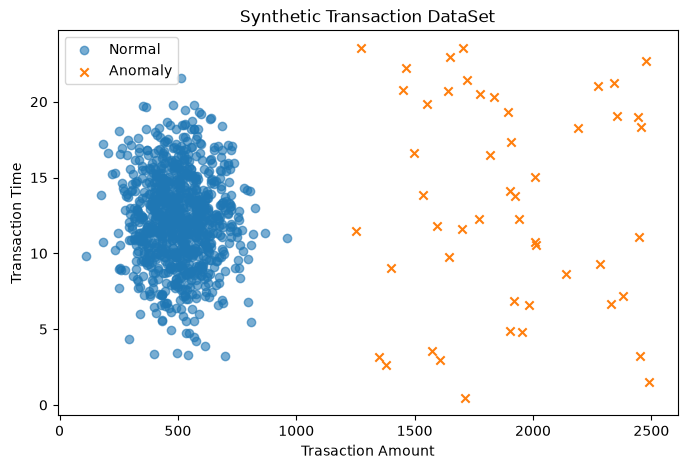

In [46]:
plt.figure(figsize=(8,5))

plt.scatter(
    df.loc[df.actual_label == 0, "transaction_amount"],
    df.loc[df.actual_label == 0, "transaction_time"],
    label="Normal",
    alpha=0.6
)

plt.scatter(
    df.loc[df.actual_label == 1, "transaction_amount"],
    df.loc[df.actual_label == 1, "transaction_time"],
    label = "Anomaly",
    marker = "x"
)

plt.xlabel("Trasaction Amount")
plt.ylabel("Transaction Time")
plt.title("Synthetic Transaction DataSet")
plt.legend()
plt.show()

In [47]:
X = df[["transaction_amount", "transaction_time"]]
y = df['actual_label']

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [48]:
iso_model = IsolationForest(
    n_estimators=100,
    contamination=0.05,
    random_state=42
)

iso_model.fit(X_scaled)
iso_model_raw = iso_model.predict(X_scaled)
iso_model_pred = (iso_model_raw == -1).astype(int)

lof = LocalOutlierFactor(
    n_neighbors=20,
    contamination=0.05
)

lof_raw = lof.fit_predict(X_scaled)
lof_pred = (lof_raw == -1).astype(int)

svm = OneClassSVM(
    kernel="rbf",
    nu = 0.05,
    gamma="scale"
)

svm.fit(X_scaled)
svm_raw = svm.predict(X_scaled)
svm_pred = (svm_raw == -1).astype(int)

predictions = {
    "Isolation Forest" : iso_model_pred,
    "LOF" : lof_pred,
    "One-Class-SVM" : svm_pred
}

In [49]:
for name, y_pred in predictions.items():
    print("\n" + "=" * 50)
    print(name)
    print("=" * 50)

    print("Confusion Matrix : ")
    print(confusion_matrix(y, y_pred, labels = [0, 1]))

    print("\nClassification Report")
    print(classification_report(
        y,
        y_pred,
        labels=[0,1],
        target_names=["Normal", "Anomaly"],
        zero_division=0
    ))



Isolation Forest
Confusion Matrix : 
[[947   3]
 [  3  47]]

Classification Report
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00       950
     Anomaly       0.94      0.94      0.94        50

    accuracy                           0.99      1000
   macro avg       0.97      0.97      0.97      1000
weighted avg       0.99      0.99      0.99      1000


LOF
Confusion Matrix : 
[[909  41]
 [ 41   9]]

Classification Report
              precision    recall  f1-score   support

      Normal       0.96      0.96      0.96       950
     Anomaly       0.18      0.18      0.18        50

    accuracy                           0.92      1000
   macro avg       0.57      0.57      0.57      1000
weighted avg       0.92      0.92      0.92      1000


One-Class-SVM
Confusion Matrix : 
[[930  20]
 [ 19  31]]

Classification Report
              precision    recall  f1-score   support

      Normal       0.98      0.98      0.98       950
 

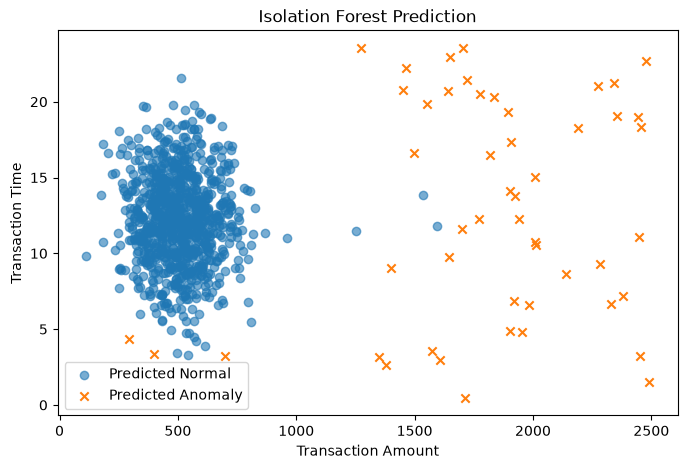

In [50]:
df['iso_prediction'] = iso_model_pred
plt.figure(figsize=(8,5))

plt.scatter(
    df.loc[df.iso_prediction == 0, "transaction_amount"],
    df.loc[df.iso_prediction == 0, "transaction_time"],
    label='Predicted Normal',
    alpha=0.6
)

plt.scatter(
    df.loc[df.iso_prediction == 1, 'transaction_amount'],
    df.loc[df.iso_prediction == 1, 'transaction_time'],
    label = "Predicted Anomaly",
    marker = 'x'
)

plt.xlabel("Transaction Amount")
plt.ylabel("Transaction Time")
plt.title("Isolation Forest Prediction")
plt.legend()
plt.show()